<a href="https://colab.research.google.com/github/halilcankaroglu/yzm511-midterm-mlp/blob/main/03_final_test.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import os, sys, json
if "google.colab" in sys.modules:
    os.chdir("/content")
    if not os.path.exists("yzm511-midterm-mlp"):
        !git clone https://github.com/halilcankaroglu/yzm511-midterm-mlp.git
    %cd /content/yzm511-midterm-mlp
    try:
        from google.colab import userdata
        token = userdata.get("GH_TOKEN")
        !git remote set-url origin https://{token}@github.com/halilcankaroglu/yzm511-midterm-mlp.git
        !git config user.name "Halil Çankaroğlu"
        !git config user.email "halil.cankaroglu@onlineseyler.com"
    except Exception:
        print("GH_TOKEN yok: yalnızca çalıştırma modu, push yapılmaz.")

SEEDS = json.load(open("configs/seeds.json")) if os.path.exists("configs/seeds.json") else None

/content/yzm511-midterm-mlp


Veri

In [3]:
import numpy as np, pandas as pd

df = pd.read_csv("data/bank-additional.csv", sep=";").drop(columns=["duration"])
split = pd.read_csv("results/dataset_split.csv")
dev_rows = split.loc[split["set"] == "dev", "row_index"].values
test_rows = split.loc[split["set"] == "test", "row_index"].values

X_dev = df.iloc[dev_rows].drop(columns=["y"]).reset_index(drop=True)
y_dev = (df.iloc[dev_rows]["y"] == "yes").astype(int).values
X_test = df.iloc[test_rows].drop(columns=["y"]).reset_index(drop=True)   # etiket yok
print(X_dev.shape, X_test.shape)

(3295, 19) (824, 19)


Tam development üzerinde iç CV (36 eğitim)

In [3]:
from src.nested_cv import run_search

manual = json.load(open("configs/manual_candidates.json"))
rand = json.load(open("configs/random_candidates.json"))
training = json.load(open("configs/training.json"))

sel, rows_all = {}, []
for method, cl in [("manual", manual), ("random", rand)]:
    rows, _, best = run_search(cl, X_dev, y_dev, training, SEEDS,
                               dict(outer="full_dev", method=method))
    rows_all.append(rows)
    sel[method] = (best, float(rows["mean_ap"].max()))
    print(f"{method}: {best} | iç CV mean AP {sel[method][1]:.4f}")
pd.concat(rows_all).to_csv("results/final_selection_results.csv", index=False)

method = max(sel, key=lambda m: sel[m][1])          # önceden tanımlı kural
code = sel[method][0]
cfg = {c["code"]: c for c in manual + rand}[code]
print("\nNihai:", method, code, cfg)

manual: M2 | iç CV mean AP 0.4250
random: R5 | iç CV mean AP 0.4230

Nihai: manual M2 {'optimizer': 'adam', 'hidden_layers': [32], 'activation': 'relu', 'scaler': 'standard', 'lr': 0.001, 'weight_decay': 0.0001, 'batch_size': 64, 'dropout': 0.0, 'clipping': False, 'scheduler': True, 'code': 'M2'}


Üç seed ile eğitim ve kilitli tahminler

In [4]:
import torch, joblib
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from src.mlp import fit_mlp, predict_proba
from src.preprocessing import build_preprocessor

os.makedirs("models", exist_ok=True)
preds = pd.DataFrame({"row_index": test_rows})
runs = []
for i, s in enumerate(SEEDS["init"]):
    res = fit_mlp(cfg, X_dev, y_dev, training, SEEDS["early_stop"], s)
    torch.save(res["model"].state_dict(), f"models/mlp_seed{i}.pt")
    joblib.dump(res["pre"], f"models/mlp_seed{i}_pre.joblib")
    if i == 0:
        res["history"].to_csv("results/final_training_history.csv", index=False)
    p = predict_proba(res, X_test)
    preds[f"p_mlp_seed{i}"] = p
    preds[f"pred_mlp_seed{i}"] = (p >= training["threshold"]).astype(int)
    runs.append(dict(seed=s, best_epoch=res["best_epoch"], epochs_run=res["epochs_run"],
                     seconds=round(res["seconds"], 1), n_params=res["n_params"]))

logreg = Pipeline([("pre", build_preprocessor("standard")),
                   ("clf", LogisticRegression(max_iter=2000))]).fit(X_dev, y_dev)
joblib.dump(logreg, "models/logreg.joblib")
p = logreg.predict_proba(X_test)[:, 1]
preds["p_logreg"], preds["pred_logreg"] = p, (p >= training["threshold"]).astype(int)

assert "y" not in preds.columns
preds.to_csv("results/test_predictions_locked.csv", index=False)

final = dict(selected_method=method, selected_code=code, config=cfg,
             inner_cv_mean_ap=sel[method][1],
             search_winners={m: dict(code=c, mean_ap=a) for m, (c, a) in sel.items()},
             primary_seed=SEEDS["init"][0], seeds=SEEDS, threshold=training["threshold"],
             training=training, seed_runs=runs)
json.dump(final, open("results/final_hyperparameters.json", "w"), indent=2, ensure_ascii=False)
pd.DataFrame(runs)

,seed,best_epoch,epochs_run,seconds,n_params
0,290162036,14,29,2.0,2017
1,290162037,12,27,1.9,2017
2,290162038,14,29,2.0,2017


In [5]:
!git pull --rebase
!git add results/final_selection_results.csv results/final_hyperparameters.json \
         results/final_training_history.csv results/test_predictions_locked.csv models/
!git commit -m "KİLİT: nihai konfigürasyon ve etiketsiz test tahminleri"
!git push

error: cannot pull with rebase: You have unstaged changes.
error: Please commit or stash them.
Author identity unknown

*** Please tell me who you are.

Run

  git config --global user.email "you@example.com"
  git config --global user.name "Your Name"

to set your account's default identity.
Omit --global to set the identity only in this repository.

fatal: unable to auto-detect email address (got 'root@a662a39ce5bd.(none)')
fatal: could not read Username for 'https://github.com': No such device or address


In [6]:
!printf "__pycache__/\n*.pyc\n.ipynb_checkpoints/\n" > .gitignore
!git pull --rebase
!git rm -r --cached -q src/__pycache__
!git add .gitignore
!git commit -m ".gitignore eklendi, __pycache__ kaldırıldı"
!git push

error: cannot pull with rebase: Your index contains uncommitted changes.
error: Please commit or stash them.
fatal: pathspec 'src/__pycache__' did not match any files
Author identity unknown

*** Please tell me who you are.

Run

  git config --global user.email "you@example.com"
  git config --global user.name "Your Name"

to set your account's default identity.
Omit --global to set the identity only in this repository.

fatal: unable to auto-detect email address (got 'root@a662a39ce5bd.(none)')
fatal: could not read Username for 'https://github.com': No such device or address


Test metrikleri ve seed kararlılığı

In [7]:
from src.metrics import compute_metrics

preds = pd.read_csv("results/test_predictions_locked.csv")
y_test = (df.loc[preds["row_index"], "y"] == "yes").astype(int).values   # etiketler ilk kez burada

test = pd.DataFrame([
    dict(model="MLP (M2, ana seed)", **compute_metrics(y_test, preds["p_mlp_seed0"].values)),
    dict(model="LogReg", **compute_metrics(y_test, preds["p_logreg"].values)),
]).set_index("model")
test.to_csv("results/test_metrics.csv")
display(test.round(3))

seed = pd.DataFrame([dict(seed=SEEDS["init"][i], **compute_metrics(y_test, preds[f"p_mlp_seed{i}"].values))
                     for i in range(3)])
seed.to_csv("results/seed_stability_results.csv", index=False)
m = ["AP", "ROC_AUC", "F1", "Sensitivity", "Specificity", "Balanced_Acc"]
display(seed[["seed"] + m].round(3))
print((seed[m].mean().round(3).astype(str) + " ± " + seed[m].std().round(3).astype(str)).to_string())

,AP,ROC_AUC,Accuracy,Precision,Sensitivity,Specificity,F1,Balanced_Acc
model,,,,,,,,
"MLP (M2, ana seed)",0.441,0.788,0.902,0.645,0.222,0.985,0.331,0.604
LogReg,0.429,0.784,0.897,0.581,0.200,0.982,0.298,0.591


,seed,AP,ROC_AUC,F1,Sensitivity,Specificity,Balanced_Acc
0,290162036,0.441,0.788,0.331,0.222,0.985,0.604
1,290162037,0.434,0.784,0.298,0.200,0.982,0.591
2,290162038,0.436,0.788,0.317,0.211,0.985,0.598


AP              0.437 ± 0.004
ROC_AUC         0.786 ± 0.002
F1              0.315 ± 0.017
Sensitivity     0.211 ± 0.011
Specificity     0.984 ± 0.002
Balanced_Acc    0.598 ± 0.006


Bootstrap %95 güven aralıkları

In [8]:
from sklearn.metrics import average_precision_score, roc_auc_score, f1_score

def bootstrap(y, p, n=1000, seed=SEEDS["base"] + 20):
    rng = np.random.default_rng(seed)
    out, skipped = [], 0
    while len(out) < n:
        i = rng.integers(0, len(y), len(y))
        if y[i].min() == y[i].max():          # tek sınıf kaldıysa atla
            skipped += 1; continue
        out.append((average_precision_score(y[i], p[i]), roc_auc_score(y[i], p[i]),
                    f1_score(y[i], (p[i] >= 0.5).astype(int), zero_division=0)))
    out = np.array(out)
    lo, hi = np.percentile(out, [2.5, 97.5], axis=0)
    return pd.DataFrame({"alt": lo, "ust": hi}, index=["AP", "ROC_AUC", "F1"]), skipped

rows = []
for name, col in [("MLP (M2, ana seed)", "p_mlp_seed0"), ("LogReg", "p_logreg")]:
    ci, skipped = bootstrap(y_test, preds[col].values)
    for met in ci.index:
        rows.append(dict(model=name, metrik=met, nokta=test.loc[name, met],
                         alt=ci.loc[met, "alt"], ust=ci.loc[met, "ust"]))
    print(name, "| tek sınıflı atlanan örneklem:", skipped)
ci_table = pd.DataFrame(rows).round(3)
ci_table.to_csv("results/test_bootstrap_ci.csv", index=False)
ci_table

MLP (M2, ana seed) | tek sınıflı atlanan örneklem: 0
LogReg | tek sınıflı atlanan örneklem: 0


,model,metrik,nokta,alt,ust
0,"MLP (M2, ana seed)",AP,0.441,0.341,0.554
1,"MLP (M2, ana seed)",ROC_AUC,0.788,0.730,0.842
2,"MLP (M2, ana seed)",F1,0.331,0.214,0.436
3,LogReg,AP,0.429,0.322,0.545
4,LogReg,ROC_AUC,0.784,0.723,0.838
5,LogReg,F1,0.298,0.188,0.400


Grafikler

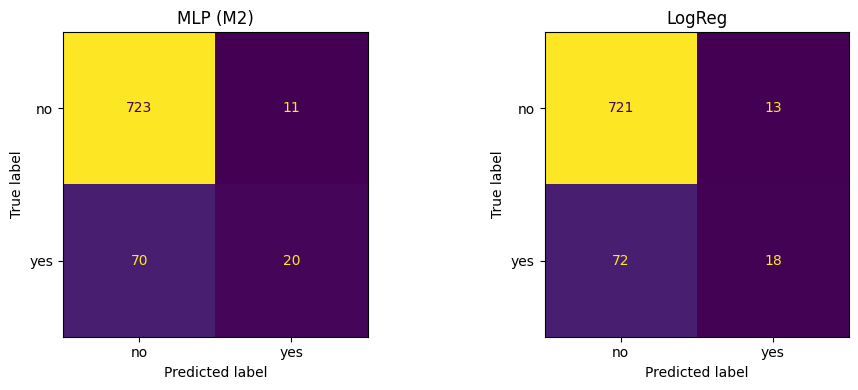

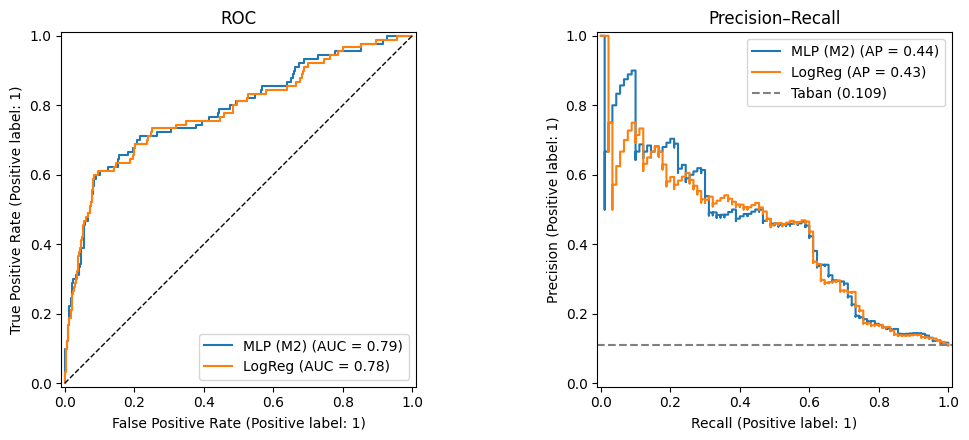

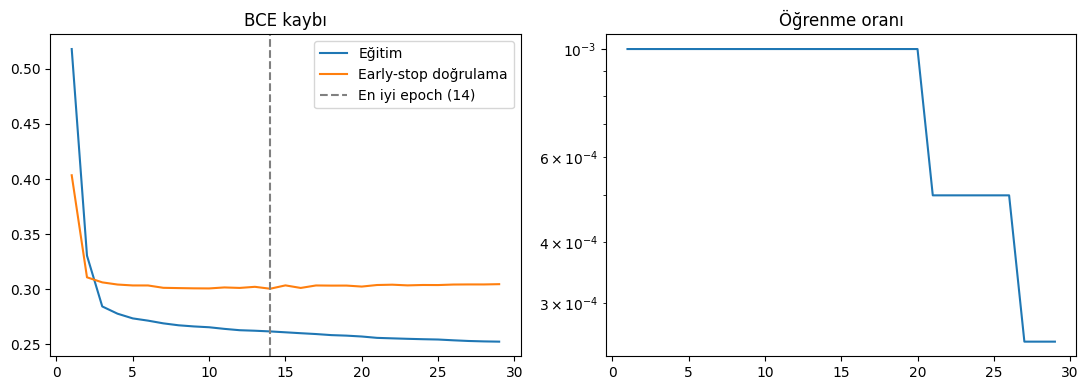

In [9]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay

models = [("MLP (M2)", "pred_mlp_seed0", "p_mlp_seed0"), ("LogReg", "pred_logreg", "p_logreg")]

# Şekil 6: confusion matrix
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, (name, pred, _) in zip(ax, models):
    ConfusionMatrixDisplay.from_predictions(y_test, preds[pred], display_labels=["no", "yes"],
                                            ax=a, colorbar=False)
    a.set_title(name)
plt.tight_layout(); plt.savefig("figures/test_confusion.png", dpi=150); plt.show()

# Şekil 7: ROC ve PR eğrileri
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
for name, _, p in models:
    RocCurveDisplay.from_predictions(y_test, preds[p], name=name, ax=ax[0])
    PrecisionRecallDisplay.from_predictions(y_test, preds[p], name=name, ax=ax[1])
ax[0].plot([0, 1], [0, 1], "k--", lw=1); ax[0].set_title("ROC")
ax[1].axhline(y_test.mean(), ls="--", c="gray", label=f"Taban ({y_test.mean():.3f})")
ax[1].legend(); ax[1].set_title("Precision–Recall")
plt.tight_layout(); plt.savefig("figures/test_roc_pr.png", dpi=150); plt.show()

# Şekil 4: nihai modelin eğitim eğrileri
h = pd.read_csv("results/final_training_history.csv")
best = json.load(open("results/final_hyperparameters.json"))["seed_runs"][0]["best_epoch"]
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(h.epoch, h.train_loss, label="Eğitim"); ax[0].plot(h.epoch, h.val_loss, label="Early-stop doğrulama")
ax[0].axvline(best, ls="--", c="gray", label=f"En iyi epoch ({best})"); ax[0].legend(); ax[0].set_title("BCE kaybı")
ax[1].plot(h.epoch, h.lr); ax[1].set_yscale("log"); ax[1].set_title("Öğrenme oranı")
plt.tight_layout(); plt.savefig("figures/final_training_curves.png", dpi=150); plt.show()

Hata analizi ve eşleştirilmiş fark

In [10]:
X_te = df.loc[preds["row_index"]].reset_index(drop=True)
X_te["grup"] = np.select(
    [(y_test == 1) & (preds.pred_mlp_seed0 == 1), (y_test == 1) & (preds.pred_mlp_seed0 == 0),
     (y_test == 0) & (preds.pred_mlp_seed0 == 1)], ["TP", "FN", "FP"], "TN")
print(X_te["grup"].value_counts())

err = X_te.groupby("grup").agg(
    n=("age", "size"), olasilik_medyan=("grup", lambda g: preds.loc[g.index, "p_mlp_seed0"].median()),
    euribor_medyan=("euribor3m", "median"), daha_once_basarili=("poutcome", lambda s: (s == "success").mean()),
    yas_medyan=("age", "median"), campaign_medyan=("campaign", "median")).round(3)
err.to_csv("results/test_error_analysis.csv")
display(err)

# İsteğe bağlı: MLP - LogReg AP farkının eşleştirilmiş bootstrap aralığı
rng = np.random.default_rng(SEEDS["base"] + 21); d = []
for _ in range(1000):
    i = rng.integers(0, len(y_test), len(y_test))
    if y_test[i].min() == y_test[i].max(): continue
    d.append(average_precision_score(y_test[i], preds.p_mlp_seed0.values[i]) -
             average_precision_score(y_test[i], preds.p_logreg.values[i]))
print(f"AP farkı (MLP - LogReg): {np.mean(d):.3f}, %95 aralık [{np.percentile(d, 2.5):.3f}, {np.percentile(d, 97.5):.3f}]")

grup
TN    723
FN     70
TP     20
FP     11
Name: count, dtype: int64


,n,olasilik_medyan,euribor_medyan,daha_once_basarili,yas_medyan,campaign_medyan
grup,,,,,,
FN,70,0.121,1.349,0.014,37.0,2.0
FP,11,0.689,0.893,0.818,47.0,1.0
TN,723,0.053,4.858,0.006,38.0,2.0
TP,20,0.692,0.732,0.850,37.5,1.0


AP farkı (MLP - LogReg): 0.012, %95 aralık [-0.013, 0.037]


In [11]:
!git pull --rebase
!git add results/test_metrics.csv results/seed_stability_results.csv results/test_bootstrap_ci.csv \
         results/test_error_analysis.csv figures/
!git commit -m "Bağımsız test: metrikler, bootstrap CI, seed kararlılığı, grafikler, hata analizi"
!git push

error: cannot pull with rebase: Your index contains uncommitted changes.
error: Please commit or stash them.
Author identity unknown

*** Please tell me who you are.

Run

  git config --global user.email "you@example.com"
  git config --global user.name "Your Name"

to set your account's default identity.
Omit --global to set the identity only in this repository.

fatal: unable to auto-detect email address (got 'root@a662a39ce5bd.(none)')
fatal: could not read Username for 'https://github.com': No such device or address


Çalışma ortamı

In [12]:
import sys, platform, subprocess
import numpy, pandas, sklearn, scipy, torch, matplotlib, seaborn, joblib

pkgs = {"numpy": numpy, "pandas": pandas, "scikit-learn": sklearn, "scipy": scipy,
        "torch": torch, "matplotlib": matplotlib, "seaborn": seaborn, "joblib": joblib}
with open("requirements.txt", "w") as f:
    for name, mod in pkgs.items():
        f.write(f"{name}=={mod.__version__.split('+')[0]}\n")
print(open("requirements.txt").read())

print("Python:", sys.version.split()[0])
print("OS:", platform.platform())
print("CPU:", subprocess.run("lscpu | grep 'Model name'", shell=True, capture_output=True, text=True).stdout.strip())
print("Çekirdek:", __import__("os").cpu_count())
print("RAM (GB):", round(int(open("/proc/meminfo").readline().split()[1]) / 1e6, 1))
print("CUDA:", torch.cuda.is_available())

numpy==2.4.6
pandas==2.2.3
scikit-learn==1.6.1
scipy==1.16.3
torch==2.14.1
matplotlib==3.10.0
seaborn==0.13.2
joblib==1.6.0

Python: 3.13.18
OS: Linux-6.6.159+-x86_64-with-glibc2.39
CPU: Model name:                              Intel(R) Xeon(R) CPU @ 2.20GHz
Çekirdek: 2
RAM (GB): 13.3
CUDA: False


In [13]:
!git pull --rebase
!git add requirements.txt
!git commit -m "requirements.txt (sabit sürümler)"
!git push

error: cannot pull with rebase: Your index contains uncommitted changes.
error: Please commit or stash them.
Author identity unknown

*** Please tell me who you are.

Run

  git config --global user.email "you@example.com"
  git config --global user.name "Your Name"

to set your account's default identity.
Omit --global to set the identity only in this repository.

fatal: unable to auto-detect email address (got 'root@a662a39ce5bd.(none)')
fatal: could not read Username for 'https://github.com': No such device or address


## Tekrarlanabilirlik kontrolü

Üç notebook sırayla baştan sona çalıştırıldıktan sonra, yeniden üretilen sonuç dosyaları repodaki commit'li sürümleriyle karşılaştırılır. Süre sütunları (`seconds`) doğası gereği her koşuda değiştiği için karşılaştırma dışındadır. Bağımsız ve temiz bir Colab oturumunda yapılan kontrolde tüm dosyalarda fark 0 bulunmuştur.

In [14]:
import io, subprocess
import numpy as np, pandas as pd

def committed(path):
    return subprocess.run(["git", "show", f"HEAD:{path}"], capture_output=True, text=True).stdout

files = ["results/dataset_split.csv", "results/eda_numeric_stats.csv",
         "results/manual_search_results.csv", "results/random_search_results.csv",
         "results/outer_cv_results.csv", "results/training_logs.csv",
         "results/final_selection_results.csv", "results/test_predictions_locked.csv",
         "results/test_metrics.csv", "results/seed_stability_results.csv"]

for f in files:
    a, b = pd.read_csv(io.StringIO(committed(f))), pd.read_csv(f)
    a, b = a.drop(columns=["seconds"], errors="ignore"), b.drop(columns=["seconds"], errors="ignore")
    if a.shape != b.shape:
        print(f"{f}: BOYUT FARKLI {a.shape} / {b.shape}"); continue
    num = a.select_dtypes("number").columns
    diff = np.abs(a[num].values - b[num].values).max() if len(num) else 0.0
    same_text = a.drop(columns=num).astype(str).equals(b.drop(columns=num).astype(str))
    print(f"{f}: maks. sayısal fark = {diff:.2e} | metin sütunları {'aynı' if same_text else 'FARKLI'}")

results/dataset_split.csv: maks. sayısal fark = 0.00e+00 | metin sütunları aynı
results/eda_numeric_stats.csv: maks. sayısal fark = 0.00e+00 | metin sütunları aynı
results/manual_search_results.csv: maks. sayısal fark = 0.00e+00 | metin sütunları aynı
results/random_search_results.csv: maks. sayısal fark = 0.00e+00 | metin sütunları aynı
results/outer_cv_results.csv: maks. sayısal fark = 0.00e+00 | metin sütunları aynı
results/training_logs.csv: maks. sayısal fark = 0.00e+00 | metin sütunları aynı
results/final_selection_results.csv: maks. sayısal fark = 0.00e+00 | metin sütunları aynı
results/test_predictions_locked.csv: maks. sayısal fark = 0.00e+00 | metin sütunları aynı
results/test_metrics.csv: maks. sayısal fark = 0.00e+00 | metin sütunları aynı
results/seed_stability_results.csv: maks. sayısal fark = 0.00e+00 | metin sütunları aynı


## Rapor şekilleri

Şekil 1: veri bölünmesi ve nested CV akışı

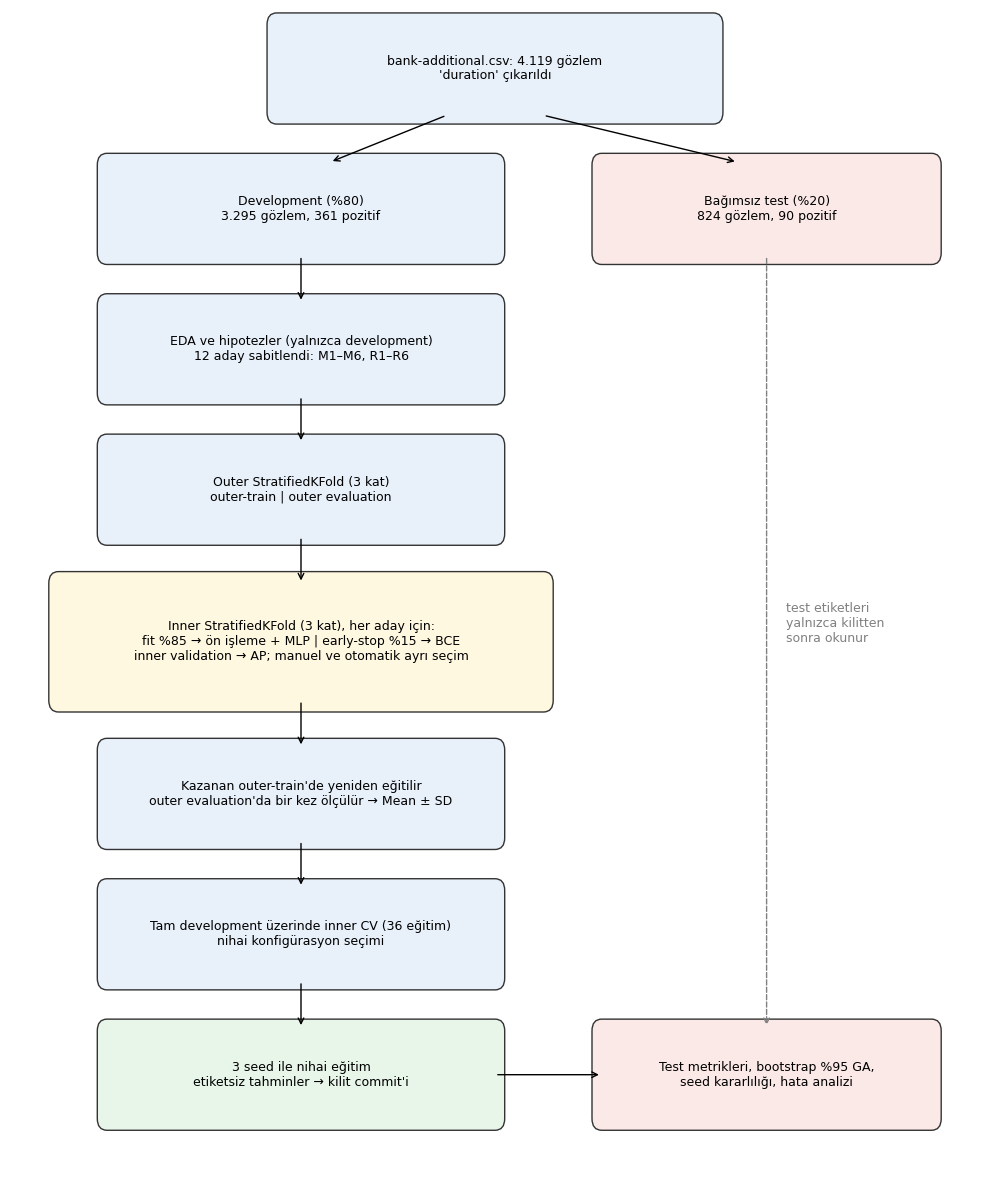

In [4]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

def box(ax, x, y, text, w=0.40, h=0.075, fc="#e8f0fa"):
    ax.add_patch(FancyBboxPatch((x - w/2, y - h/2), w, h, boxstyle="round,pad=0.01", fc=fc, ec="#333"))
    ax.text(x, y, text, ha="center", va="center", fontsize=9)

def arrow(ax, x1, y1, x2, y2, **kw):
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1), arrowprops=dict(arrowstyle="->", **kw))

fig, ax = plt.subplots(figsize=(10, 12)); ax.axis("off")
box(ax, .5, .95, "bank-additional.csv: 4.119 gözlem\n'duration' çıkarıldı", w=.45)
box(ax, .30, .83, "Development (%80)\n3.295 gözlem, 361 pozitif")
box(ax, .78, .83, "Bağımsız test (%20)\n824 gözlem, 90 pozitif", w=.34, fc="#fbe9e7")
box(ax, .30, .71, "EDA ve hipotezler (yalnızca development)\n12 aday sabitlendi: M1–M6, R1–R6")
box(ax, .30, .59, "Outer StratifiedKFold (3 kat)\nouter-train | outer evaluation")
box(ax, .30, .46, "Inner StratifiedKFold (3 kat), her aday için:\nfit %85 → ön işleme + MLP | early-stop %15 → BCE\ninner validation → AP; manuel ve otomatik ayrı seçim",
    w=.50, h=.10, fc="#fff8e1")
box(ax, .30, .33, "Kazanan outer-train'de yeniden eğitilir\nouter evaluation'da bir kez ölçülür → Mean ± SD")
box(ax, .30, .21, "Tam development üzerinde inner CV (36 eğitim)\nnihai konfigürasyon seçimi")
box(ax, .30, .09, "3 seed ile nihai eğitim\netiketsiz tahminler → kilit commit'i", fc="#e8f5e9")
box(ax, .78, .09, "Test metrikleri, bootstrap %95 GA,\nseed kararlılığı, hata analizi", w=.34, fc="#fbe9e7")

arrow(ax, .45, .91, .33, .87); arrow(ax, .55, .91, .75, .87)
for y1, y2 in [(.79, .75), (.67, .63), (.55, .51), (.41, .37), (.29, .25), (.17, .13)]:
    arrow(ax, .30, y1, .30, y2)
arrow(ax, .50, .09, .61, .09)
arrow(ax, .78, .79, .78, .13, ls="--", color="gray")
ax.text(.80, .46, "test etiketleri\nyalnızca kilitten\nsonra okunur", fontsize=9, color="gray")
ax.set_xlim(0, 1); ax.set_ylim(0, 1)
plt.tight_layout(); plt.savefig("figures/fig1_nested_cv_flow.png", dpi=150); plt.show()

Şekil 3: nihai MLP mimarisi ve parametre sayısı

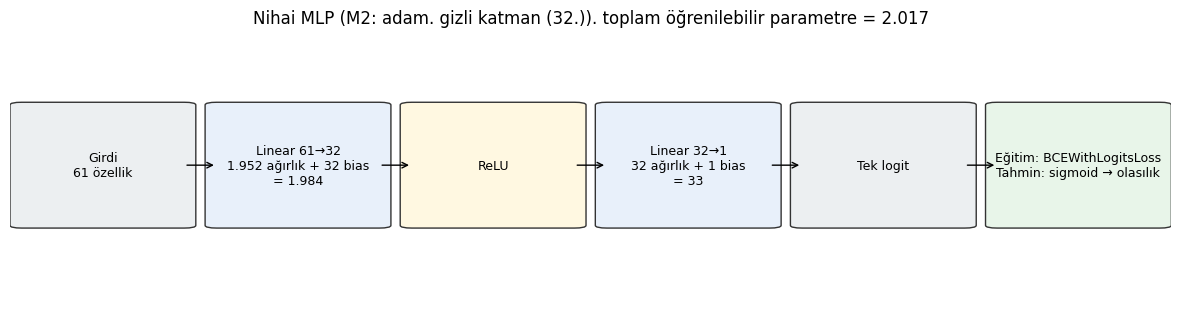

[('net.0.weight', torch.Size([32, 61])), ('net.0.bias', torch.Size([32])), ('net.2.weight', torch.Size([1, 32])), ('net.2.bias', torch.Size([1]))] 2017


In [5]:
import joblib, torch

final = json.load(open("results/final_hyperparameters.json"))
pre = joblib.load("models/mlp_seed0_pre.joblib")
n_in = pre.transform(X_dev.head(1)).shape[1]
state = torch.load("models/mlp_seed0.pt")
layers = [(k, v.shape) for k, v in state.items()]
n_total = sum(v.numel() for v in state.values())
h = final["config"]["hidden_layers"][0]

fig, ax = plt.subplots(figsize=(12, 3.2)); ax.axis("off")
items = [(f"Girdi\n{n_in} özellik", "#eceff1"),
         (f"Linear {n_in}→{h}\n{n_in*h:,} ağırlık + {h} bias\n= {n_in*h + h:,}".replace(",", "."), "#e8f0fa"),
         ("ReLU", "#fff8e1"),
         (f"Linear {h}→1\n{h} ağırlık + 1 bias\n= {h + 1}", "#e8f0fa"),
         ("Tek logit", "#eceff1"),
         ("Eğitim: BCEWithLogitsLoss\nTahmin: sigmoid → olasılık", "#e8f5e9")]
xs = np.linspace(.08, .92, len(items))
for (t, c), x in zip(items, xs):
    box(ax, x, .5, t, w=.14, h=.45, fc=c)
for a, b in zip(xs[:-1], xs[1:]):
    arrow(ax, a + .07, .5, b - .07, .5)
ax.set_title(f"Nihai MLP ({final['selected_code']}: {final['config']['optimizer']}, "
             f"gizli katman ({h},)), toplam öğrenilebilir parametre = {n_total:,}".replace(",", "."))
ax.set_xlim(0, 1); ax.set_ylim(0, 1)
plt.tight_layout(); plt.savefig("figures/fig3_mlp_architecture.png", dpi=150); plt.show()
print(layers, n_total)

In [6]:
!git pull --rebase
!git add figures/fig1_nested_cv_flow.png figures/fig3_mlp_architecture.png
!git commit -m "Rapor şekilleri: akış şeması ve MLP mimarisi"
!git push

Already up to date.
[main d80b866] Rapor şekilleri: akış şeması ve MLP mimarisi
 2 files changed, 0 insertions(+), 0 deletions(-)
 create mode 100644 figures/fig1_nested_cv_flow.png
 create mode 100644 figures/fig3_mlp_architecture.png
Enumerating objects: 7, done.
Counting objects: 100% (7/7), done.
Delta compression using up to 2 threads
Compressing objects: 100% (5/5), done.
Writing objects: 100% (5/5), 198.97 KiB | 11.05 MiB/s, done.
Total 5 (delta 2), reused 0 (delta 0), pack-reused 0
remote: Resolving deltas: 100% (2/2), completed with 2 local objects.
To https://github.com/halilcankaroglu/yzm511-midterm-mlp.git
   9b920d2..d80b866  main -> main
